# Snap-through of a shallow circular arch: Fung and Kaplan (1952)

Y. C. Fung and A. Kaplan, *Buckling of low arches or curved beams of small curvature*, NACA TN 2840, November 1952 (NTRS 19930083579).

A shallow circular arch, hinged at both ends, under a sinusoidal dead load snaps through: the load-deflection path has a maximum, where the arch jumps to an inverted configuration under load control, and a minimum, with negative loads, between which the path is unstable. The path is traced through both limit points with the arc-length methods of `structsolve`, Riks and Crisfield, each with the convergence criteria `'crisfield'` and `'relative'`, and compared with the solution of the equilibrium equations of Fung and Kaplan, solved here for the circular arch:

- span $L = 100$, thickness $t = 1$, rise parameter $\lambda_1 = 2.2$, i.e. radius $\rho_0 = 1015.66$ and rise $L^2/(8 \rho_0) = 1.23 t$;
- isotropic, $\nu = 0$ (the load parameter $R$ does not depend on $E$);
- hinged ends without initial thrust, $\beta = 1$ and $S = 0$;
- reference: the symmetric equilibrium path of Eqs. (15) and (45), its maximum and minimum loads.

In [1]:
import os
import time
from importlib.metadata import version

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.optimize import brentq
from structsolve import Analysis

import panels
import scf_validation_utils as su
from scf_validation_utils import pct, markdown_table, run_or_load

# True runs panels again, otherwise the results saved in RESULTS are loaded
RERUN = False
RESULTS = 'results'

## Reference: Fung and Kaplan (1952)

Fung and Kaplan write the initial and the deflected center lines of the arch as $y_0 = \sum_m a_m L \sin(m \pi x/L)$ and $y = \sum_m b_m L \sin(m \pi x/L)$, Eqs. (2) and (3), $y$ positive upwards, and the lateral load per unit length, positive downwards, as $q = q_0 \sum_m k_m \sin(m \pi x/L)$, Eq. (12). With the nondimensional parameters of Eq. (14),

$$\lambda_m = \frac{a_m L}{2} \sqrt{\frac{A}{I}}, \qquad B_m = \frac{b_m L}{2} \sqrt{\frac{A}{I}}, \qquad R = \frac{q_0 L^4}{2 \pi^4 E I} \sqrt{\frac{A}{I}}, \qquad S = \frac{H_0 L^2}{\pi^2 E I},$$

and $\beta = \alpha/(\alpha + EA/L)$, Eq. (10), where $H_0$ is the initial thrust and $\alpha$ the spring constant of the end support, the equilibrium equations are, Eq. (15),

$$B_m \left( \beta \sum_{n=1}^\infty n^2 B_n^2 - \beta \sum_{n=1}^\infty n^2 \lambda_n^2 + m^2 - S \right) = -\frac{R}{m^2} k_m + \lambda_m (m^2 - S) \qquad (m = 1, 2, 3, \dots)$$

For hinged ends without initial thrust, $\beta = 1$ ($\alpha = \infty$) and $S = 0$; for the sinusoidal load, $q = q_0 \sin(\pi x/L)$, $k_1 = 1$ and $k_m = 0$ for $m > 1$. The circular arc of radius $\rho_0$ is, Eq. (45),

$$y_0 = \frac{1}{2 \rho_0} x (L - x) = \frac{4 L^2}{\pi^3 \rho_0} \sum_{n = 1, 3, 5, \dots} \frac{1}{n^3} \sin \frac{n \pi x}{L},$$

with the rise $L^2/(8 \rho_0)$, i.e. $\lambda_n = \lambda_1/n^3$ for odd $n$ and $\lambda_n = 0$ for even $n$. With $T = \sum_n n^2 B_n^2 - \sum_n n^2 \lambda_n^2$, Eqs. (15) become

$$B_1 (T + 1) = \lambda_1 - R, \qquad B_m (T + m^2) = m^2 \lambda_m = \frac{\lambda_1}{m} \quad (m = 3, 5, \dots), \qquad B_m (T + m^2) = 0 \quad (m = 2, 4, \dots).$$

On the symmetric path the even $B_m$ vanish, and the path is given parametrically by $T$: $B_m = \lambda_1/(m (T + m^2))$ for odd $m \ge 3$, $B_1^2 = T + \sum_n n^2 \lambda_n^2 - \sum_{m \ge 3} m^2 B_m^2$ from the definition of $T$, with both signs of $B_1$, and $R = \lambda_1 - B_1 (T + 1)$. The sums are truncated at $m = 20001$, their terms decreasing as $m^{-4}$. Since $\mathrm{d} B_1^2/\mathrm{d}T = 1 + 2 \lambda_1^2 \sum_{m \ge 3} (T + m^2)^{-3}$, the limit points, $\mathrm{d}R/\mathrm{d}T = 0$, satisfy

$$\left( 1 + 2 \lambda_1^2 \sum_{m = 3, 5, \dots} \frac{1}{(T + m^2)^3} \right) (T + 1) + 2 B_1^2 = 0,$$

the same $T$ for both signs of $B_1$: the maximum ($B_1 > 0$) and the minimum ($B_1 < 0$) are symmetric about $\lambda_1$, $R_{max} + R_{min} = 2 \lambda_1$. For the sinusoidal arch, $\lambda_m = 0$ for $m \ge 2$, these are Eqs. (23), $B_1^3 - B_1 (\lambda_1^2 - 1) = \lambda_1 - R$, and (25), $(B_1)_{cr} = \sqrt{(\lambda_1^2 - 1)/3}$ and $R_{cr} = \lambda_1 + \sqrt{4 (\lambda_1^2 - 1)^3/27}$, shown for comparison.

The equation of $m = 2$ admits $B_2 \ne 0$ at $T = -4$, the bifurcation into the unsymmetric mode of Eqs. (26)-(29). For the sinusoidal arch it precedes the limit point, condition (3) after Eq. (29), when $B_1 = \sqrt{\lambda_1^2 - 4}$ of Eq. (29) is larger than $(B_1)_{cr}$ of Eq. (25), i.e. for $\lambda_1^2 > 5.5$. With $\lambda_1 = 2.2$ the path from $R = 0$, $T = 0$, reaches the limit point before $T = -4$ (below), and the two bifurcation points lie on the unstable part of the path, between the maximum and the minimum; $T$ does not go below its value at $B_1 = 0$, $-4.64$, so the other even modes, $T = -m^2$ with $m \ge 4$, do not appear. The maximum of the symmetric path is therefore the critical load.

The deflection compared is that of the midspan, positive downwards, $-w_C = y_0(L/2) - y(L/2) = -(2/\sqrt{A/I}) \sum_m (B_m - \lambda_m) \sin(m \pi/2)$, with $\sqrt{A/I} = \sqrt{12}/t$.

In [2]:
LAM1 = 2.2
MS = np.arange(3, 20002, 2)  # odd m >= 3
SUM_N2LAM2 = LAM1**2*(1 + np.sum(MS**-4.))  # sum n^2 lambda_n^2, n odd


def b1_squared(T):
    return T + SUM_N2LAM2 - LAM1**2*np.sum((T + MS**2.)**-2)


def fk_point(T, sign):
    r'''R, -w_C/t and B_1 of the symmetric path at T, B_1 with the sign ``sign``'''
    B1 = sign*np.sqrt(max(b1_squared(T), 0.))
    Bm = LAM1/(MS*(T + MS**2.))
    sin_m = np.sin(MS*np.pi/2)
    w_t = (B1 - LAM1 + np.sum((Bm - LAM1/MS**3.)*sin_m))/np.sqrt(3)
    return LAM1 - B1*(T + 1), -w_t, B1


def stationary(T):
    return (1 + 2*LAM1**2*np.sum((T + MS**2.)**-3))*(T + 1) + 2*b1_squared(T)


T_LIM = brentq(stationary, -3.9, -3., xtol=1e-14)
FK_MAX, FK_MIN = fk_point(T_LIM, 1), fk_point(T_LIM, -1)
FK_BIF = fk_point(-4., 1), fk_point(-4., -1)

# the symmetric path, from R = 0 (T = 0, B_1 = lambda_1) to R = 6 on the inverted branch
T0 = brentq(b1_squared, -6., -4.)
T6 = brentq(lambda T: fk_point(T, -1)[0] - 6., 0., 10.)
ref_path = np.array([fk_point(T, 1) for T in np.linspace(0., T0, 2001)]
                    + [fk_point(T, -1) for T in np.linspace(T0, T6, 2001)[1:]])
assert np.all(np.diff(ref_path[:, 1]) > 0)  # -w_C increases along the path

R25 = LAM1 + np.sqrt(4/27*(LAM1**2 - 1)**3)
rows = [['maximum', '%.4f' % T_LIM, '%.4f' % FK_MAX[2], '%.4f' % FK_MAX[0], '%.4f' % FK_MAX[1]],
        ['minimum', '%.4f' % T_LIM, '%.4f' % FK_MIN[2], '%.4f' % FK_MIN[0], '%.4f' % FK_MIN[1]],
        ['bifurcation, $B_1 > 0$', '-4', '%.4f' % FK_BIF[0][2], '%.4f' % FK_BIF[0][0], '%.4f' % FK_BIF[0][1]],
        ['bifurcation, $B_1 < 0$', '-4', '%.4f' % FK_BIF[1][2], '%.4f' % FK_BIF[1][0], '%.4f' % FK_BIF[1][1]],
        ['$B_1 = 0$, smallest $T$ of the path', '%.4f' % T0, '0', '%.4f' % fk_point(T0, 1)[0], '%.4f' % fk_point(T0, 1)[1]],
        ['end of the path', '%.4f' % T6, '%.4f' % fk_point(T6, -1)[2], '6', '%.4f' % fk_point(T6, -1)[1]]]
display(Markdown(markdown_table(['circular arch, $\\lambda_1 = %g$' % LAM1, '$T$', '$B_1$', '$R$', '$-w_C/t$'], rows)))
display(Markdown('Sinusoidal arch with the same $\\lambda_1$, Eq. (25): $(B_1)_{cr}$ = %.4f, $R_{cr}$ = %.4f; '
                 '$R_{max} + R_{min}$ of the circular arch: %.6f'
                 % (np.sqrt((LAM1**2 - 1)/3), R25, FK_MAX[0] + FK_MIN[0])))

| circular arch, $\lambda_1 = 2.2$ | $T$ | $B_1$ | $R$ | $-w_C/t$ |
|---|---|---|---|---|
| maximum | -3.4462 | 1.1373 | 4.9822 | 0.6413 |
| minimum | -3.4462 | -1.1373 | -0.5822 | 1.9546 |
| bifurcation, $B_1 > 0$ | -4 | 0.8381 | 4.7143 | 0.8222 |
| bifurcation, $B_1 < 0$ | -4 | -0.8381 | -0.3143 | 1.7900 |
| $B_1 = 0$, smallest $T$ of the path | -4.6406 | 0 | 2.2000 | 1.3182 |
| end of the path | 0.6244 | -2.3393 | 6 | 2.6179 |

Sinusoidal arch with the same $\lambda_1$, Eq. (25): $(B_1)_{cr}$ = 1.1314, $R_{cr}$ = 5.0963; $R_{max} + R_{min}$ of the circular arch: 4.400000

## panels model

The arch is a strip of a cylindrical panel of radius $\rho_0$, `cylshell_clpt_sanders`, made by `su.make_shell`, in cylindrical bending: the axial width $a = 10$ with free curved edges, $x = 0, a$, and the straight edges, $y = 0, b$, hinged, $u = v = w = 0$ with the rotations free, which are the hinged ends without end flexibility or initial thrust of Fung and Kaplan, $\beta = 1$ and $S = 0$. With $\nu = 0$ the strip has no anticlastic coupling and its stiffnesses per unit width, $E t^3/12$ and $E t$, are $E I$ and $E A$ of the beam per unit width, such that $R = q_0 L^4 \sqrt{A/I}/(2 \pi^4 E I) = p_0 L^4 \sqrt{12}/(2 \pi^4 (E t^3/12) t)$ with the pressure amplitude $p_0 = q_0/a$.

From $\lambda_1 = (a_1 L/2) \sqrt{12}/t$ and Eq. (45), $a_1 L = \lambda_1 t/\sqrt{3}$ and $\rho_0 = 4 L^2/(\pi^3 a_1 L)$. The arc has the chord $L = 2 \rho_0 \sin \theta$ and the length $b = 2 \rho_0 \theta$. The dead pressure $p = -p_0 \sin(\pi y/b)$, `add_pressure_load(..., cte=False)`, acts along the normal of the undeformed arc, inwards, with $p_0$ for the reference load $R_{ref} = 6$, above the maximum, such that $R = 6 \lambda$ with the load factor $\lambda$ of `structsolve`. The model differs from the shallow-arch theory of Fung and Kaplan, which neglects $(\mathrm{d}y/\mathrm{d}x)^2$ against 1, by terms of the order of $\theta^2$: the load along the arc length $y$ and the normal of the arc instead of the span coordinate $x$ and the vertical, the exact circular arc instead of the parabola of Eq. (45) (rise $\rho_0 (1 - \cos \theta)$ instead of $L^2/(8 \rho_0)$), and Sanders' kinematics.

The Ritz approximation has $3 \times 14$ terms ($x \times y$). The four paths use `NL_method = 'arc_length_riks'` or `'arc_length_crisfield'` and `convergence = 'crisfield'` or `'relative'`, with the default tolerance `relTOL` and `initialInc = maxInc = 0.05`, since `structsolve` caps the arc length of a step at `max(maxInc, initial arc length)`; `maxArcLength` is large enough for each path to end at the load factor 1, $R = 6$, on the inverted branch:

```python
an = Analysis(s.calc_fext, s.calc_fint, s.calc_kC, s.calc_kG)
an.NL_method = method
an.convergence = convergence
an.initialInc = an.maxInc = 0.05
an.maxArcLength = 1.e6
increments, cs = an.static(NLgeom=True, silent=True)
```

The limit points are the first local maximum of the load along the path and the following local minimum, refined with a parabola through the three points around each, $R$ as a function of $w_C$, which decreases monotonically along the paths. The panels model contains the unsymmetric modes; `asym` is the largest difference between the deflections at $y = b/4$ and $3b/4$ along the path, which checks that the paths remain on the symmetric branch through the bifurcation points. Two more runs, Riks with Crisfield's criterion, check the convergence of the Ritz approximation, $3 \times 20$ terms, and the resolution of the path, `initialInc = maxInc = 0.02`.

**Stored results and run times.** The stored results, `results/fk1952_shallow_arches.json`, were computed with `panels` 0.14.0, `structsolve` 0.9.3 and `composites` 0.10.1 (the versions of `panels` and `structsolve` are also stored in the file). The run times, the column `time` below, are the wall-clock times of `an.static()` measured on the machine of that computation, an AMD Ryzen 7 PRO 250 laptop with Windows 11, one run at a time; they indicate the cost and are not benchmarks. With `RERUN = True`, `compute()` recomputes everything, and measures the times again, with the installed `panels` and `structsolve`.

In [3]:
L, T_ARCH, WIDTH, E = 100., 1., 10., 1.e5
A1L = LAM1*T_ARCH/np.sqrt(3)
RHO0 = 4*L**2/(np.pi**3*A1L)
THETA = np.arcsin(L/2/RHO0)
B_ARC = 2*RHO0*THETA
RREF = 6.
P0 = RREF*2*np.pi**4*(E*T_ARCH**3/12)/(L**4*np.sqrt(12)/T_ARCH)
METHODS = [('Riks', 'arc_length_riks'), ('Crisfield', 'arc_length_crisfield')]
CRITERIA = ('crisfield', 'relative')
print('rho0 = %.4f, theta = %.5f rad, b = %.4f, rise rho0 (1 - cos theta) = %.4f, L^2/(8 rho0) = %.4f'
      % (RHO0, THETA, B_ARC, RHO0*(1 - np.cos(THETA)), L**2/(8*RHO0)))
print('default relTOL of structsolve:', Analysis().relTOL)


def arch(n=14):
    s = su.make_shell('clpt', WIDTH, B_ARC, [0.], [T_ARCH], [(E, 0.)], r=RHO0, bcs='FFFF', m=3, n=n)
    for edge in ('y1', 'y2'):
        for field in 'uvw':
            setattr(s, edge + field, 0.)
    s._rebuild()
    s.add_pressure_load(lambda x, y: -P0*np.sin(np.pi*y/B_ARC), cte=False)
    return s


def run(method, convergence, n=14, inc=0.05):
    s = arch(n)
    an = Analysis(s.calc_fext, s.calc_fint, s.calc_kC, s.calc_kG)
    an.NL_method = method
    an.convergence = convergence
    an.initialInc = an.maxInc = inc
    an.maxArcLength = 1.e6
    t0 = time.time()
    increments, cs = an.static(NLgeom=True, silent=True)
    elapsed = time.time() - t0
    wc = [su.center(s, c) for c in cs]
    asym = max(abs(su.center(s, c, y=B_ARC/4) - su.center(s, c, y=3*B_ARC/4)) for c in cs)
    return dict(R=(RREF*np.asarray(increments)).tolist(), wc=wc, time=elapsed, asym=asym,
                ndof=int(s.get_size()), relTOL=an.relTOL)


def compute():
    res = dict(versions=dict(panels=panels.__version__, structsolve=version('structsolve')), paths={}, checks={})
    for label, method in METHODS:
        for convergence in CRITERIA:
            res['paths']['%s/%s' % (label, convergence)] = run(method, convergence)
    res['checks']['3 x 20 terms'] = run('arc_length_riks', 'crisfield', n=20)
    res['checks']['inc = 0.02'] = run('arc_length_riks', 'crisfield', inc=0.02)
    return res


def limit_points(o):
    r'''Maximum and following minimum of R along the path, refined with a parabola R(w_C)'''
    R = np.r_[0., o['R']]
    w = np.r_[0., o['wc']]
    assert np.all(np.diff(w) < 0)
    dR = np.diff(R)
    i = int(np.flatnonzero(dR < 0)[0])
    j = i + int(np.flatnonzero(dR[i:] > 0)[0])
    out = []
    for k in (i, j):
        c = np.polyfit(w[k-1:k+2], R[k-1:k+2], 2)
        wk = -c[1]/(2*c[0])
        out.append((float(np.polyval(c, wk)), float(-wk/T_ARCH)))
    return out


res = run_or_load(os.path.join(RESULTS, 'fk1952_shallow_arches.json'), compute, rerun=RERUN)
print('stored results computed with panels %(panels)s, structsolve %(structsolve)s' % res['versions'])

rho0 = 1015.6599, theta = 0.04925 rad, b = 100.0404, rise rho0 (1 - cos theta) = 1.2315, L^2/(8 rho0) = 1.2307
default relTOL of structsolve: 1e-09
stored results computed with panels 0.14.0, structsolve 0.9.3


## Limit loads

Maximum and minimum loads, $R_{max}$ and $R_{min}$, and the midspan deflections at them, $-w_C/t$, against the symmetric path of Eqs. (15) and (45), with the differences in parentheses (relative for $R_{max}$, absolute for $R_{min}$). `steps` is the number of converged steps of the whole path, up to $R = 6$, and `time` its run time, see above.

In [4]:
def limit_row(label, o, d=4):
    (Rmax, wmax), (Rmin, wmin) = limit_points(o)
    f = '%%.%df (%%+.%df)' % (d, d)
    return [label, '%%.%df (%%+.3f%%%%)' % d % (Rmax, pct(Rmax, FK_MAX[0])), f % (wmax, wmax - FK_MAX[1]),
            f % (Rmin, Rmin - FK_MIN[0]), f % (wmin, wmin - FK_MIN[1]),
            '%%.%df' % d % (Rmax + Rmin), len(o['R']), '%.1e' % o['asym'], '%.1f s' % o['time']]


header = ['method / criterion', '$R_{max}$', '$-w_C/t$ at $R_{max}$', '$R_{min}$', '$-w_C/t$ at $R_{min}$',
          '$R_{max} + R_{min}$', 'steps', 'asym', 'time']
rows = [['Fung and Kaplan, Eqs. (15), (45)', '%.4f' % FK_MAX[0], '%.4f' % FK_MAX[1], '%.4f' % FK_MIN[0],
         '%.4f' % FK_MIN[1], '%.4f' % (FK_MAX[0] + FK_MIN[0]), '', '', '']]
rows += [limit_row(key, o) for key, o in res['paths'].items()]
display(Markdown(markdown_table(header, rows)))
base = res['paths']['Riks/crisfield']
for key, o in res['paths'].items():
    print('%-19s largest difference from Riks/crisfield along the path: R %.1e, w_C/t %.1e'
          % (key, np.abs(np.subtract(o['R'], base['R'])).max(), np.abs(np.subtract(o['wc'], base['wc'])).max()/T_ARCH))

| method / criterion | $R_{max}$ | $-w_C/t$ at $R_{max}$ | $R_{min}$ | $-w_C/t$ at $R_{min}$ | $R_{max} + R_{min}$ | steps | asym | time |
|---|---|---|---|---|---|---|---|---|
| Fung and Kaplan, Eqs. (15), (45) | 4.9822 | 0.6413 | -0.5822 | 1.9546 | 4.4000 |  |  |  |
| Riks/crisfield | 4.9858 (+0.074%) | 0.6422 (+0.0008) | -0.5883 (-0.0061) | 1.9581 (+0.0035) | 4.3976 | 129 | 8.9e-14 | 19.2 s |
| Riks/relative | 4.9858 (+0.074%) | 0.6422 (+0.0008) | -0.5883 (-0.0061) | 1.9581 (+0.0035) | 4.3976 | 129 | 8.9e-14 | 19.6 s |
| Crisfield/crisfield | 4.9858 (+0.074%) | 0.6422 (+0.0008) | -0.5883 (-0.0061) | 1.9581 (+0.0035) | 4.3976 | 129 | 1.4e-13 | 19.1 s |
| Crisfield/relative | 4.9858 (+0.074%) | 0.6422 (+0.0008) | -0.5883 (-0.0061) | 1.9581 (+0.0035) | 4.3976 | 129 | 1.4e-13 | 19.0 s |

Riks/crisfield      largest difference from Riks/crisfield along the path: R 0.0e+00, w_C/t 0.0e+00
Riks/relative       largest difference from Riks/crisfield along the path: R 5.8e-09, w_C/t 3.5e-10
Crisfield/crisfield largest difference from Riks/crisfield along the path: R 8.6e-08, w_C/t 4.4e-09
Crisfield/relative  largest difference from Riks/crisfield along the path: R 8.6e-08, w_C/t 4.4e-09


### Convergence checks

Riks with Crisfield's criterion: the model above ($3 \times 14$ terms, `initialInc = maxInc = 0.05`), $3 \times 20$ terms, and a shorter step, `initialInc = maxInc = 0.02`.

In [5]:
rows = [limit_row('3 x 14 terms, inc = 0.05', res['paths']['Riks/crisfield'], d=6)]
rows += [limit_row(key, o, d=6) for key, o in res['checks'].items()]
display(Markdown(markdown_table(['run'] + header[1:], rows)))

| run | $R_{max}$ | $-w_C/t$ at $R_{max}$ | $R_{min}$ | $-w_C/t$ at $R_{min}$ | $R_{max} + R_{min}$ | steps | asym | time |
|---|---|---|---|---|---|---|---|---|
| 3 x 14 terms, inc = 0.05 | 4.985849 (+0.074%) | 0.642160 (+0.000848) | -0.588278 (-0.006111) | 1.958128 (+0.003521) | 4.397571 | 129 | 8.9e-14 | 19.2 s |
| 3 x 20 terms | 4.985849 (+0.074%) | 0.642160 (+0.000848) | -0.588278 (-0.006111) | 1.958128 (+0.003521) | 4.397571 | 129 | 1.7e-13 | 49.7 s |
| inc = 0.02 | 4.985831 (+0.074%) | 0.642083 (+0.000770) | -0.588294 (-0.006128) | 1.958166 (+0.003560) | 4.397537 | 321 | 1.2e-13 | 45.9 s |

## Load-deflection path

The four paths of panels (they coincide) against the symmetric path of Fung and Kaplan, with the limit points of the reference (circles) and the bifurcation points at $T = -4$ (squares). The end of the path, $R = 6$ on the inverted branch, is also compared, at the same load, where the deflection is well conditioned.

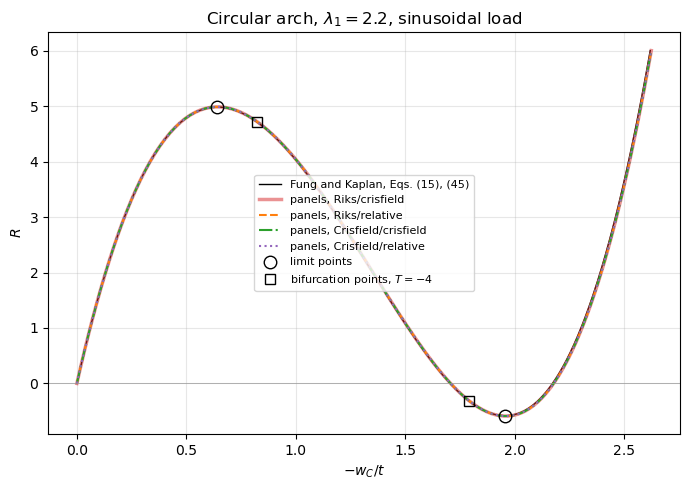

R = 6 on the inverted branch: -w_C/t = 2.6227 (panels), 2.6179 (Fung and Kaplan), difference +0.0047


In [6]:
styles = {'Riks/crisfield': dict(color='tab:red', lw=2.5, alpha=0.5), 'Riks/relative': dict(color='tab:orange', ls='--'),
          'Crisfield/crisfield': dict(color='tab:green', ls='-.'), 'Crisfield/relative': dict(color='tab:purple', ls=':')}
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(ref_path[:, 1], ref_path[:, 0], 'k-', lw=1, label='Fung and Kaplan, Eqs. (15), (45)')
for key, o in res['paths'].items():
    ax.plot(-np.r_[0., o['wc']]/T_ARCH, np.r_[0., o['R']], label='panels, %s' % key, **styles[key])
ax.plot([FK_MAX[1], FK_MIN[1]], [FK_MAX[0], FK_MIN[0]], 'o', mfc='none', mec='k', ms=9, label='limit points')
ax.plot([p[1] for p in FK_BIF], [p[0] for p in FK_BIF], 's', mfc='none', mec='k', ms=7,
        label='bifurcation points, $T = -4$')
ax.axhline(0., color='0.6', lw=0.5)
ax.set_xlabel('$-w_C/t$')
ax.set_ylabel('$R$')
ax.set_title('Circular arch, $\\lambda_1 = %g$, sinusoidal load' % LAM1)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

o = res['paths']['Riks/crisfield']
w_end_ref = fk_point(T6, -1)[1]
print('R = 6 on the inverted branch: -w_C/t = %.4f (panels), %.4f (Fung and Kaplan), difference %+.4f'
      % (-o['wc'][-1]/T_ARCH, w_end_ref, -o['wc'][-1]/T_ARCH - w_end_ref))

## Discussion

- **Limit loads.** The maximum load of panels, $R_{max} = 4.9858$, is 0.074% above that of Eqs. (15) and (45), 4.9822, at a midspan deflection larger by $0.0008 t$; the minimum, $-0.5883$, is $0.0061$ below $-0.5822$, i.e. 0.11% of the load range $R_{max} - R_{min}$, at a deflection larger by $0.0035 t$. These differences, and $R_{max} + R_{min} = 4.3976$ instead of $2 \lambda_1 = 4.4$ for the shallow-arch theory, are of the order of $\theta^2 = 2.4 \times 10^{-3}$, the order of the terms in which the model differs from the theory of Fung and Kaplan (see the model above).
- **Path.** The paths of panels follow the reference through the maximum, the unstable part and the minimum to the inverted branch; at $R = 6$ the deflection is $2.6227 t$ against $2.6179 t$ (0.18%). On the steep branches a comparison of the loads at the same deflection is ill-conditioned and is not used.
- **Bifurcation.** The paths remain symmetric, `asym` $\le 1.7 \times 10^{-13}$, through the two bifurcation points at $T = -4$ on the unstable part of the path, which a symmetric load and a symmetric arch do not trigger; the unsymmetric branch of Eqs. (26)-(29) is not traced here, and with $\lambda_1 = 2.2$ it does not change the critical load, the maximum of the symmetric path.
- **Arc-length methods and convergence criteria.** The four paths coincide, 129 steps each, with differences of at most $9 \times 10^{-8}$ in $R$ along the path, and the same limit loads: the default tolerance, `relTOL = 1e-9`, is reached with either criterion at every step. Riks and Crisfield take the same time on this small model (126 degrees of freedom).
- **Convergence.** With $3 \times 20$ terms the limit loads are unchanged to six decimals, and with `initialInc = maxInc = 0.02` (321 steps) they change by $2 \times 10^{-5}$: the model and the path are converged, and the differences from the reference are those of the model, not of the discretisation.
- **Shape of the arch.** The sinusoidal arch with the same $\lambda_1$ has $R_{cr} = 5.0963$, Eq. (25), 2.3% above the circular arch: the higher harmonics of the circular arc, $\lambda_n = \lambda_1/n^3$, lower the maximum load, and they are needed in the reference.